# Data analytics for the corpus

**Author:** Amittai Siavava

What is in the [ai-tech-articles](https://huggingface.co/datasets/siavava/ai-tech-articles)
dataset: how many articles, from where, from when, and how long they are.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

from ai_tech_articles import load_dataframe

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = plt.rcParams["axes.spines.right"] = False

df = load_dataframe()
df["text_chars"] = df["text"].str.len()
df["date"] = pd.to_datetime(df["date"], errors="coerce")
print(f"{len(df):,} articles · {df['domain'].nunique()} domains · years {df.year.min()}–{df.year.max()}")
df.describe(include="all").T.head(9)

## Articles per year


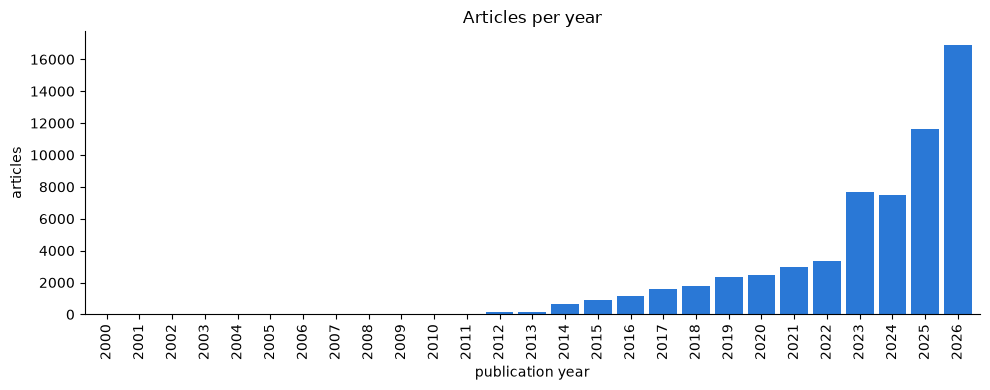

year
2019     2354
2020     2474
2021     2966
2022     3376
2023     7708
2024     7489
2025    11619
2026    16910
dtype: int64

In [2]:
per_year = df.groupby("year").size()
ax = per_year.plot.bar(width=0.85, color="#2a78d6")
ax.set_xlabel("publication year")
ax.set_ylabel("articles")
ax.set_title("Articles per year")
plt.tight_layout()
plt.show()
per_year.tail(8)

## Monthly volume where we have full dates (2023 onwards)


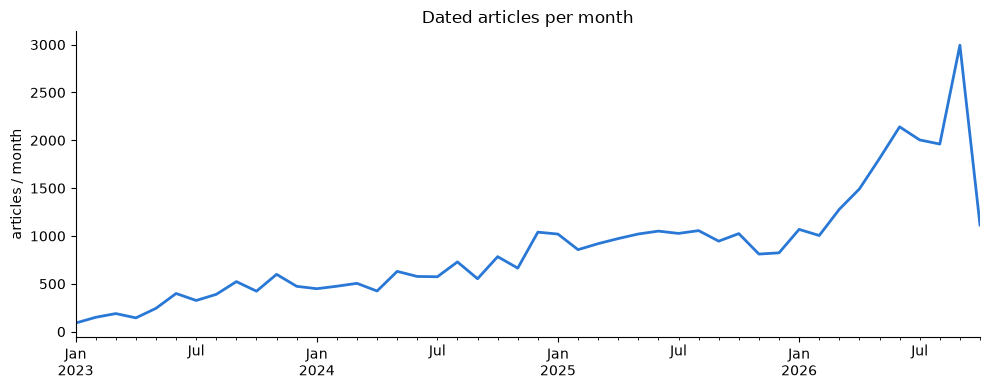

39,757 dated articles; busiest month: September 2026 (2,994)


In [3]:
dated = df[df["date"].notna() & (df["date"] >= "2023-01-01")]
monthly = dated.set_index("date").resample("MS").size()
ax = monthly.plot(color="#2a78d6", linewidth=2)
ax.set_xlabel("")
ax.set_ylabel("articles / month")
ax.set_title("Dated articles per month")
plt.tight_layout()
plt.show()
print(f"{len(dated):,} dated articles; busiest month: {monthly.idxmax():%B %Y} ({monthly.max():,})")

## Sources


In [ ]:
top = df["domain"].value_counts().head(25)
ax = top.sort_values().plot.barh(color="#2a78d6")
ax.set_xlabel("articles")
ax.set_title("Top 25 domains")
for i, v in enumerate(top.sort_values()):
  ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()
print(f"{df['domain'].nunique()} domains; the largest holds {top.iloc[0] / len(df):.1%} of all rows")

## How long are the articles?


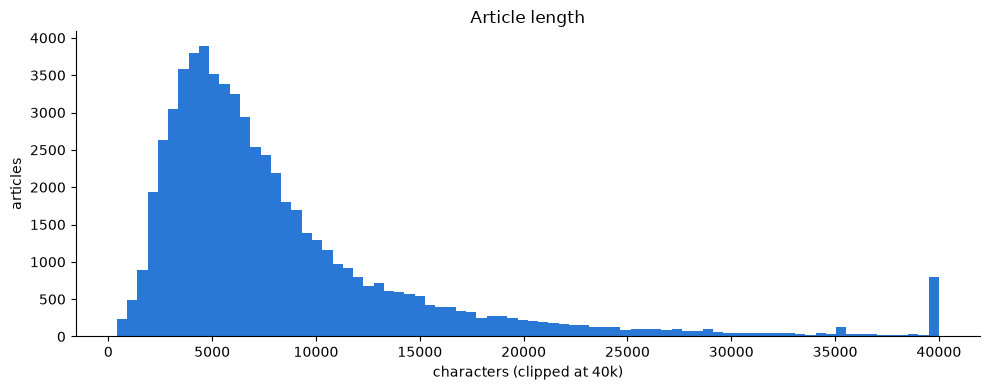

count     61543.0
mean       8675.0
50%        6362.0
min         404.0
max      323561.0
Name: text_chars, dtype: float64

In [5]:
ax = df["text_chars"].clip(upper=40_000).plot.hist(bins=80, color="#2a78d6")
ax.set_xlabel("characters (clipped at 40k)")
ax.set_ylabel("articles")
ax.set_title("Article length")
plt.tight_layout()
plt.show()
df["text_chars"].describe()[["count", "mean", "50%", "min", "max"]].round(0)

## A few titles


In [6]:
for y in (2016, 2020, 2023, 2024, 2025, 2026):
  print(f"--- {y} ---")
  for t in df[df.year == y].sample(4, random_state=y)["title"]:
    print("  ", t[:110])

--- 2016 ---
   Searching for the Algorithms Underlying Life | Quanta Magazine
   Facebook Is Teaching Chatbots to Talk With Help From Facebook | WIRED
   Games accounted for 32% of Windows Store downloads in Q4 2015, over 85% of in-app purchases | VentureBeat
   Asia’s AI Agenda: Aware, but Unprepared?
--- 2020 ---
   June 2020 | VentureBeat
   MIT presents AI frameworks that compress models and encourage agents to explore | VentureBeat
   Scientists Discovered 'Mini-Computers' in Human Neurons—and That's Great News for AI
   E3 2020 cancellation: Game industry reacts to physical vs. digital marketing | VentureBeat
--- 2023 ---
   DeepMind says its new AI coding engine is as good as an average human programmer - The Verge
   The ethics of generative AI: How we can harness this powerful technology - ZDNET
   Facebook is researching AI systems that see, hear, and remember everything you do - The Verge
   How one elite university is approaching ChatGPT this school year
--- 2024 ---
   AW